# Arbeitspaket (AP) 2: Datenbeschaffung, Datenaufbereitung & explorative Datenanalyse

### Persönliche Angaben (bitte ergänzen) und Prüfungsregeln

<table>
  <tr><td>Vorname:</td><td>Leonardo</td></tr>
  <tr><td>Nachname:</td><td>Mininni</td></tr>
  <tr><td>Immatrikulationsnummer:</td><td>15-181-928</td></tr>
  <tr><td>Modul:</td><td>Data Science</td></tr>
  <tr><td>Prüfungsdatum / Raum / Zeit:</td><td>[18.10.2026] / Raum: [MU O2.013] / [08:00 – 12:00]</td></tr>
  <tr><td>Erlaubte Hilfsmittel:</td><td>Es gelten die Prüfungsregeln (PDF-Dokument auf EXAM-Moodle).</td></tr>
  <tr><td>Nicht erlaubt:</td><td>Es gelten die Prüfungsregeln (PDF-Dokument auf EXAM-Moodle).</td></tr>
  <tr><td>Technische Probleme:</td><td>Wenden Sie sich bei technischen Problemen umgehend an die Prüfungsaufsicht.</td></tr>
</table>

## Bewertungskriterien

**(max. erreichbare Punkte: 40)**

<table>
  <thead>
    <tr><th>Teil</th><th>Thema</th><th>Aufgaben</th><th>Punkte</th></tr>
  </thead>
  <tbody>
    <tr><td>A</td><td>Konzeptfragen: Datenaufbereitung &amp; explorative Datenanalyse</td><td>A1–A3</td><td>12</td></tr>
    <tr><td>B</td><td>Fehleranalyse Python-Code (Shop-Daten)</td><td>B1–B2</td><td>16</td></tr>
    <tr><td>C</td><td>Python-Code schreiben: Web Scraping, Datenaufbereitung &amp; EDA</td><td>C1–C3</td><td>12</td></tr>
    <tr><td><b>Total</b></td><td></td><td><b>8 Aufgaben</b></td><td><b>40</b></td></tr>
  </tbody>
</table>

### Bewertungsschema

Jede Aufgabe wird für sich und **als Ganzes** bewertet. Ihre Punktzahl steht in der Überschrift.

<table>
  <thead>
    <tr><th>Kategorie</th><th>Beschreibung</th><th>Bewertung</th><th>4 Pkt</th><th>8 Pkt</th></tr>
  </thead>
  <tbody>
    <tr><td>Korrekt</td><td>Vollständig und fachlich einwandfrei: Antwort bzw. Begründung korrekt und nachvollziehbar; bei Code-Aufgaben liefert der Python-Code das richtige Ergebnis</td><td>100%</td><td>4</td><td>8</td></tr>
    <tr><td>Minimale Mängel</td><td>Kleine Fehler (z.B. falsche Sortierung, fehlende Rundung, fehlende Achsenbeschriftung) oder Begründung ungenau bzw. unvollständig</td><td>75%</td><td>3</td><td>6</td></tr>
    <tr><td>Mittlere Mängel</td><td>Grössere Fehler (z.B. fehlende Spalten, falsche Filterung) oder Begründung fehlt bzw. ist fachlich falsch</td><td>50%</td><td>2</td><td>4</td></tr>
    <tr><td>Gravierende Mängel</td><td>Problem bzw. Ansatz erkennbar, aber Lösung oder Schlussfolgerung im Kern falsch (z.B. Problem richtig benannt, aber falsch behoben; im Code: ungeeigneter Lösungsweg wie falscher Join-Typ, falsche Tabelle oder falsche Datei)</td><td>25%</td><td>1</td><td>2</td></tr>
    <tr><td>Nicht lauffähig / nicht sinnvoll</td><td>Antwort fehlt, Code nicht lauffähig (z.B. Syntaxfehler) oder kein Bezug zur Aufgabe</td><td>0%</td><td>0</td><td>0</td></tr>
  </tbody>
</table>

Treffen mehrere Mängel zusammen, zählt der schwerste. Alternative, fachlich korrekte Lösungswege werden ebenfalls als korrekt gewertet.

## Hinweise zu den Daten

Alle Daten stammen vom **fiktiven** Schweizer Online-Shop «PhoneMarkt» und liegen **lokal** im gleichen Verzeichnis wie dieses Notebook. Für die Prüfung ist **kein Internetzugriff** auf Websites oder APIs nötig.

<table>
  <thead>
    <tr><th>Datei</th><th>Format</th><th>Inhalt</th></tr>
  </thead>
  <tbody>
    <tr><td><code>html/shop_page_1.html</code> … <code>shop_page_3.html</code></td><td>HTML</td><td>Gespeicherte Produktlisten-Seiten (3 Seiten mit Paginierung)</td></tr>
    <tr><td><code>html/product_detail.html</code></td><td>HTML</td><td>Gespeicherte Detailseite eines Geräts (Preisverlauf, technische Daten)</td></tr>
    <tr><td><code>reviews.json</code></td><td>JSON</td><td>Gespeicherte Antwort der Reviews-API: Liste mit Kundenbewertungen pro <code>product_id</code></td></tr>
    <tr><td><code>smartphones_clean.csv</code></td><td>CSV</td><td>Aufbereitete Shop-Daten: Formate vereinheitlicht, Duplikate entfernt — <b>inhaltlich nicht geprüft</b></td></tr>
  </tbody>
</table>

Die Spaltenbeschreibungen finden Sie im Sheet **«Description»**, die Datenquellen im Sheet **«Data Sources»** der beiliegenden Datei `smartphone_data.xlsx`. Die HTML-Dateien können Sie zur Ansicht auch im Browser oder als Text im Editor öffnen.

**Antworten auf Konzeptfragen** und **Begründungen** tragen Sie bitte direkt in die vorgesehenen Markdown-Zellen ein.

## Setup (wird nicht bewertet)

In [2]:
# Libraries
import os
import re
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from bs4 import BeautifulSoup

# Ignore warnings
import warnings
warnings.filterwarnings('ignore')

# Get current working directory
print(os.getcwd())

/workspaces/DS_HS2026_LNW/DS_HS2026_LNW_I_Examples/AP02/AP02 Mock Exam


### Produktlisten-Seiten scrapen → `df_raw`

Der folgende Code liest die drei gespeicherten Produktlisten-Seiten mit BeautifulSoup ein (analog zur Übung `skipass_data.ipynb`). Jede Produktkarte (`<div class="product-card">`) wird zu einer Zeile im Data Frame `df_raw`. Die Werte werden **als Text** übernommen (Spalten mit Endung `_raw`) und noch nicht bereinigt.

In [3]:
# Initialize list for the extracted rows
rows = []

# Loop over the three listing pages
for page in [1, 2, 3]:

    # Read html from file
    with open(f'html/shop_page_{page}.html', 'r', encoding='utf-8') as file:
        html_content = file.read()

    # Parse the HTML content
    soup = BeautifulSoup(html_content, 'html.parser')

    # Locate the product cards and extract values
    for card in soup.select('div.product-card'):
        row_data = [card['data-product-id'],
                    card.select('span.brand')[0].get_text().replace('\xa0', '').strip(),
                    card.select('span.model')[0].get_text().replace('\xa0', '').strip(),
                    card.select('li.storage')[0].get_text().replace('\xa0', '').strip(),
                    card.select('li.color')[0].get_text().replace('\xa0', '').strip(),
                    card.select('li.screen')[0].get_text().replace('\xa0', '').strip(),
                    card.select('li.battery')[0].get_text().replace('\xa0', '').strip(),
                    card.select('span.price')[0].get_text().replace('\xa0', '').strip(),
                    card.select('span.availability')[0].get_text().replace('\xa0', '').strip()]
        rows.append(row_data)

# Create a DataFrame
df_raw = pd.DataFrame(rows, columns=['product_id', 'brand', 'model', 'storage_raw', 'color',
                                     'screen_raw', 'battery_raw', 'price_raw', 'availability'])

# Show dimensions and first rows
print('Number of rows and columns:', df_raw.shape)
df_raw.head()

Number of rows and columns: (148, 9)


,product_id,brand,model,storage_raw,color,screen_raw,battery_raw,price_raw,availability
0,PM-10001,Xiaomi,Redmi Note 14 Pro 5G,256GB,Midnight Black,"6.67"" Display",5'110mAh,CHF 299.–,Sofort lieferbar
1,PM-10002,OnePlus,OnePlus 13,256GB,Arctic Dawn,"6.82"" Display",6'000mAh,CHF 899.–,Lieferbar in 2–5 Tagen
2,PM-10003,Google,Pixel 10 Pro,512GB,Obsidian,"6.3"" Display",4'870mAh,CHF 1'249.–,Sofort lieferbar
3,PM-10004,Samsung,Galaxy A36 5G,128GB,Awesome Lavender,"6.7"" Display",5'000mAh,CHF 339.–,Sofort lieferbar
4,PM-10005,Samsung,Galaxy Z Fold7,1TB,Jetblack,"8.0"" Display",4'400mAh,Preis auf Anfrage,Vorbestellung


### Aufbereitete Shop-Daten laden → `df_clean`

In [4]:
# Import data from csv to pandas dataframe named 'df_clean'
df_clean = pd.read_csv('smartphones_clean.csv')

# Show dimensions and first rows
print('Number of rows and columns:', df_clean.shape)
df_clean.head()

Number of rows and columns: (142, 9)


,product_id,brand,model,storage_gb,color,screen_inch,battery_mah,price_chf,availability
0,PM-10001,Xiaomi,Redmi Note 14 Pro 5G,256,Midnight Black,6.67,5110,299.0,Sofort lieferbar
1,PM-10002,OnePlus,OnePlus 13,256,Arctic Dawn,6.82,6000,899.0,Lieferbar in 2–5 Tagen
2,PM-10003,Google,Pixel 10 Pro,512,Obsidian,6.30,4870,1249.0,Sofort lieferbar
3,PM-10004,Samsung,Galaxy A36 5G,128,Awesome Lavender,6.70,5000,339.0,Sofort lieferbar
4,PM-10005,Samsung,Galaxy Z Fold7,1024,Jetblack,8.00,4400,NaN,Vorbestellung


> **Hinweis:** Alle Aufgaben sind voneinander unabhängig. Verändern Sie `df_raw` und `df_clean` bitte nicht direkt, sondern arbeiten Sie in jeder Aufgabe mit einem eigenen Data Frame (z.B. `df_B1`, `df_C2`).

---

<div style="background-color:#2E4057; color:white; padding:16px 24px; border-radius:6px; font-size:18px; margin-top:8px;">
&#9654;&nbsp; <strong>Ab hier beginnt die bewertete Prüfung — 40 Punkte</strong><br>
<span style="font-size:15px; font-weight:normal;">Tragen Sie Ihre Antworten direkt in die vorgesehenen Zellen ein und führen Sie alle Code-Zellen aus.</span>
</div>

In [5]:
# DATAFRAME ANALYSIEREN (Einschub MINL)

#Gesamten DataFrame anzeigen
display(df_smartphone)                                                          #DataFrame mit allen Spalten anzeigen
                                                                                #Bei grossen DataFrames werden Zeilen standardmässig gekürzt

# Verfügbare Spalten anzeigen
print(df_smartphone.columns)                                                    #Alle Spaltennamen des DataFrames anzeigen

# Grösse des DataFrames anzeigen
print(df_smartphone.shape)                                                      #Anzahl Zeilen und Spalten als Tupel ausgeben

# Missing Values analysieren
print(df_smartphone.isna().sum())                                               #Anzahl fehlender Werte (NaN/None) pro Spalte anzeigen
                                                                                #isna(): Fehlende Werte erkennen (True = fehlend)
                                                                                #sum(): True-Werte pro Spalte zählen

print(df_smartphone.isna().sum().sum())                                         #Gesamtanzahl aller fehlenden Werte im DataFrame anzeigen

display(df_smartphone[df_smartphone.isna().any(axis=1)])                        #Alle Datensätze anzeigen, die mindestens einen fehlenden Wert enthalten
                                                                                #any(axis=1): Prüfen, ob mindestens eine Spalte pro Zeile NaN enthält

# Teuerstes Smartphone anzeigen
display(df_smartphone.nlargest(1, 'price'))                                     #Datensatz mit dem höchsten Preis anzeigen
                                                                                #nlargest(1): Grössten Wert inklusive der zugehörigen Zeile zurückgeben

# Alternative: Über Sortierung
display(df_smartphone.sort_values(by='price', ascending=False).head(1))         #Nach Preis absteigend sortieren und erste Zeile anzeigen
                                                                                #ascending=False: Höchste Werte zuerst
                                                                                #head(1): Nur den ersten Datensatz anzeigen

# Die 10 teuersten Smartphones anzeigen
display(df_smartphone.nlargest(10, 'price'))                                    #Die zehn Smartphones mit den höchsten Preisen anzeigen

# Nur den höchsten Preis ermitteln
print(df_smartphone['price'].max())                                             #Maximalen Preis zurückgeben, ohne die übrigen Smartphone-Informationen

# Nur den niedrigsten Preis ermitteln
print(df_smartphone['price'].min())                                             #Minimalen Preis zurückgeben

# Die 10 günstigsten Smartphones anzeigen
display(df_smartphone.nsmallest(10, 'price'))                                   #Die zehn Smartphones mit den niedrigsten Preisen anzeigen

#ANPASSEN: df_smartphone an den verwendeten DataFrame anpassen
#ANPASSEN: 'price' an die gewünschte numerische Spalte anpassen
#ANPASSEN: nlargest(1), nlargest(10), nsmallest(10) und head(1) an die gewünschte Anzahl Datensätze anpassen
#NICHTS ANPASSEN: isna(), max(), min(), nlargest(), nsmallest() und sort_values() als Methoden
#VORAUSSETZUNG: pandas wurde als pd importiert; die Preisspalte enthält numerische Werte
#ACHTUNG: display.max_rows=None kann bei sehr grossen DataFrames zu einer riesigen und langsamen Ausgabe führen
#ACHTUNG: Bei mehreren Smartphones mit identischem Höchstpreis zeigt nlargest(1) nur eines davon
#ERKENNTNIS: isna().sum() zählt fehlende Werte pro Spalte; isna().sum().sum() zählt alle fehlenden Werte
#ERKENNTNIS: max()/min() liefern nur einen Wert; nlargest()/nsmallest() liefern vollständige Datensätze

#Wirklich alle Zeilen und Spalten anzeigen
xxxx (löschen) with pd.option_context('display.max_rows', None, 'display.max_columns', None):  #Temporär sämtliche Zeilen und Spalten anzeigen
    display(df_smartphone)                                                      #Vollständigen DataFrame ohne Kürzung ausgeben

SyntaxError: invalid syntax (2372005236.py, line 55)

---
## Teil A – Konzeptfragen (12 Punkte)

*Antworten ohne Bezug zu den Shop-Daten von «PhoneMarkt» werden nicht gewertet.*

### A1 (4 Punkte)

Bei 8 der 142 Geräte zeigt der Shop statt eines Preises den Text «Preis auf Anfrage». Laut Shop-Betreiber wird der Preis ausgeblendet, wenn er eine interne Preisschwelle übersteigt.

a) Um welchen Mechanismus fehlender Werte handelt es sich (MCAR, MAR oder MNAR)? Begründen Sie.

b) Ein Analyst entfernt diese 8 Geräte mit `dropna()` und berichtet anschliessend den durchschnittlichen Gerätepreis des Shops. Welchen Effekt hat das Entfernen auf das Ergebnis?

In [ ]:
print('Missing values per column:\n', df_clean.isna().sum()) 
display(df_raw[df_raw['price_raw'] == 'Preis auf Anfrage'])         #In df_clean wurde dies schon bereinigt



Missing values per column:
 product_id      0
brand           0
model           0
storage_gb      0
color           0
screen_inch     0
battery_mah     0
price_chf       8
availability    0
dtype: int64


,product_id,brand,model,storage_raw,color,screen_raw,battery_raw,price_raw,availability
4,PM-10005,Samsung,Galaxy Z Fold7,1TB,Jetblack,"8.0"" Display",4'400mAh,Preis auf Anfrage,Vorbestellung
24,PM-10025,Samsung,Galaxy Z Fold7,1TB,Blue Shadow,"8.0"" Display",4'400mAh,Preis auf Anfrage,Sofort lieferbar
40,PM-10041,Samsung,Galaxy Z Fold7,512GB,Blue Shadow,"8.0"" Display",4'400mAh,Preis auf Anfrage,Sofort lieferbar
56,PM-10054,Google,Pixel 10 Pro Fold,1TB,Moonstone,"8.0"" Display",5'015mAh,Preis auf Anfrage,Sofort lieferbar
85,PM-10083,Google,Pixel 10 Pro Fold,1TB,Jade,"8.0"" Display",5'015mAh,Preis auf Anfrage,Sofort lieferbar
89,PM-10087,Samsung,Galaxy Z Fold7,512GB,Jetblack,"8.0"" Display",4'400mAh,Preis auf Anfrage,Sofort lieferbar
132,PM-10127,Google,Pixel 10 Pro Fold,512GB,Jade,"8.0"" Display",5'015mAh,Preis auf Anfrage,Lieferbar in 2–5 Tagen
145,PM-10140,Google,Pixel 10 Pro Fold,512GB,Moonstone,"8.0"" Display",5'015mAh,Preis auf Anfrage,Lieferbar in 2–5 Tagen


**Ihre Antwort:**

> 
- a) MNAR, das Fehlen hängt vom Preis selbst ab
- b) dropna() entfernt standardmässig jede Zeile, die mind. einen fehlenden Wert enthält 

### A2 (4 Punkte)

Für die Spalte `price_chf` in `smartphones_clean.csv` liefert pandas folgendes Ergebnis:

```
df_clean['price_chf'].describe()          df_clean['price_chf'].skew()
count      134.00                          9.19
mean       992.89
std       1126.48
min        159.00
25%        479.00
50%        899.00
75%       1199.00
max      12990.00
```

Beschreiben Sie die Verteilung der Preise anhand dieser Kennzahlen. Welches Lagemass eignet sich besser, um den «typischen» Gerätepreis zu berichten, und warum? Nennen Sie eine geeignete Grafik, um Ihre Einschätzung zu überprüfen.

**Ihre Antwort:**

> [Hier eintragen]
- Verteilung der Preise: 
- Der Median fehlt in dieser Auflistung, der Mean ist anfällig für Ausreisser
- Histogramm kann helfen, Schiefe zu erkennen
- **Skewness > 0:** Rechtsschiefe Verteilung (Right-Skewed) → Langer Ausläufer nach rechts; wenige sehr hohe Werte
- Skewness und Kurtosis allein reichen nicht aus, um die vollständige Verteilung oder Normalverteilung zu beurteilen. Deshalb zusätzlich grafische Methoden wie Histogramme oder QQ-Plots verwenden

### A3 (4 Punkte)

Ein Kollege verbindet die Shop-Daten mit den Kundenbewertungen aus `reviews.json` und berechnet die Korrelation zwischen `price_chf` und `avg_score` (Durchschnitt der Kundenbewertungen, 1–5 Sterne):

```
df[['price_chf', 'avg_score']].corr()     # Ergebnis: r = 0.34
```

Er folgert: *«Preis und Kundenzufriedenheit hängen kaum zusammen.»*

Nennen und begründen Sie **zwei** fachliche Einwände gegen diese Vorgehensweise bzw. Schlussfolgerung.

**Ihre Antwort:**
- Die Pearson-Korrelation misst die Richtung und Stärke des linearen Zusammenhangs zwischen zwei numerischen Variablen
- Zweck: Erkennen, welche numerischen Variablen miteinander zusammenhängen, wie stark dieser Zusammenhang ist und ob er positiv oder negativ verläuft
- r > 0: Positiver Zusammenhang → höhere Werte einer Variable gehen tendenziell mit höheren Werten der anderen einher

- Es gibt also einen positiven Zusammenhang. Die Aussage des Kollegen ist falsch

**Wichtig:**
- Korrelation ≠ Kausalität: Ein statistischer Zusammenhang beweist keinen Ursache-Wirkungs-Zusammenhang
- Pearson misst nur lineare Zusammenhänge: Eine nichtlineare Beziehung kann trotz r ≈ 0 bestehen
- Ausreisser: Können die Pearson-Korrelation stark beeinflussen
- Fehlende Werte (NaN): pandas berücksichtigt für jedes Spaltenpaar nur Beobachtungen, bei denen beide Werte vorhanden sind
- Konstante Spalten: Besitzen eine undefinierte Pearson-Korrelation (NaN)

---
## Teil B – Fehleranalyse Python-Code (16 Punkte)

*Jeder Code läuft fehlerfrei durch, liefert aber ein falsches oder irreführendes Ergebnis. Die tatsächlichen Ergebnisse sind angegeben.*

### B1 (8 Punkte)

**Ziel:** Kennzahlen für das Shop-Sortiment aus den gescrapten Rohdaten `df_raw`: Anzahl Geräte, Anzahl Geräte ohne Preisangabe und Median-Preis in CHF.

```python
# Select columns for the analysis
df_B1 = df_raw[['product_id', 'brand', 'model', 'storage_raw', 'color', 'price_raw']]

# Extract numerical values from price_raw
price = []
for i in df_B1['price_raw']:
    d1 = re.findall(r"\d+", i)
    try:
        d2 = int(d1[0])
    except:
        d2 = None
    price.append(d2)

# Save as new variable in the pandas data frame
df_B1['price_chf'] = pd.Series(price, dtype="Int64")

# Show key figures
print('Anzahl Geräte:            ', df_B1.shape[0])
print('Anzahl ohne Preisangabe:  ', df_B1['price_chf'].isnull().sum())
print('Median-Preis (CHF):       ', df_B1['price_chf'].median())
```

Tatsächliches Ergebnis:

```
Anzahl Geräte:             148
Anzahl ohne Preisangabe:   8
Median-Preis (CHF):        314.0
```

Der Shop gibt auf jeder Seite an, dass er **142 Artikel** führt. Beispiele für Werte in `price_raw`: `CHF 899.–`, `CHF 1'249.–`, `Preis auf Anfrage`.

**Aufgabe:** Schreiben Sie den korrigierten Code in die Zelle «Korrigierter Code» (die Kommentare des ursprünglichen Codes sind als Gerüst vorgegeben), sodass die Kennzahlen stimmen. Begründen Sie jede Änderung gegenüber dem ursprünglichen Code.

**Begründung der Änderungen:**

> [Hier eintragen]
- Werden 148 anstatt 142 Geräte ausgegeben, liegt das klar daran, dass duplicated values drin sind
- Diese können mit print("Anzahl Duplikate vorher:", df_B1.duplicated().sum()) angezeigt werden
- df_B1 = df_B1.drop_duplicates() löscht diese raus
- print("Anzahl Duplikate nachher:", df_B1.duplicated().sum()) zeigt die Anzahl nach der Duplikat-Löschung


**Korrigierter Code:**

In [ ]:
# Korrigierten Code unter den Kommentaren eintragen

# Select columns for the analysis

# Extract numerical values from price_raw

# Save as new variable in the pandas data frame

# Show key figures

# Select columns for the analysis
df_B1 = df_raw[['product_id', 'brand', 'model', 'storage_raw', 'color', 'price_raw']]

# Extract numerical values from price_raw
price = []
for i in df_B1['price_raw']:
    d1 = re.findall(r"\d+", i)
    try:
        d2 = d2 = int(''.join(d1))                                              #Anpassung MINL
                                                                                #d1[0] nimmt nur die erste gefundene Zahl
                                                                                #''.join(d1) verbindet sämtliche gefundenen Zahlenteile zu einer Zeichenfolge
                                                                                #int() wandelt die Zeichenfolge anschliessend in eine Ganzzahl um
    except:
        d2 = None
    price.append(d2)

# Save as new variable in the pandas data frame
df_B1['price_chf'] = pd.Series(price, dtype="Int64")

print("Anzahl Duplikate vorher:", df_B1.duplicated().sum())                     #Anpassung MINL
df_B1 = df_B1.drop_duplicates()                                                 #Anpassung MINL
print("Anzahl Duplikate nachher:", df_B1.duplicated().sum())                    #Anpassung MINL
df_B1 = df_B1.reset_index(drop=True)                                            #Setzt den Index zurück und nummeriert die Zeilen neu

# Show key figures
print('Anzahl Geräte:            ', df_B1.shape[0])
print('Anzahl ohne Preisangabe:  ', df_B1['price_chf'].isnull().sum())
print('Median-Preis (CHF):       ', df_B1['price_chf'].median())




Anzahl Duplikate vorher: 6
Anzahl Duplikate nachher: 0
Anzahl Geräte:             142
Anzahl ohne Preisangabe:   8
Median-Preis (CHF):        899.0


### B2 (8 Punkte)

**Ziel:** Herausfinden, welche Marke im Sortiment am teuersten ist (auf Basis von `df_clean`).

```python
# Select columns for the analysis
df_B2 = df_clean[['brand', 'price_chf']]

# Price per brand
df_B2.groupby(['brand']).mean().round(2).sort_values(by='price_chf', ascending=False)
```

Tatsächliches Ergebnis (Ausschnitt):

```
           price_chf
brand
Samsung      1298.70
Apple        1083.71
Sony         1057.33
Google       1054.91
OnePlus       702.75
...
```

Die Produktmanagerin ist skeptisch: *«Samsung hat viele günstige A-Modelle im Sortiment — das kann nicht stimmen.»*

**Aufgabe:** Untersuchen Sie die Daten mit geeigneten EDA-Methoden, finden Sie die Ursache für das irreführende Ergebnis und schreiben Sie den korrigierten Code in die Zelle «Korrigierter Code» (die Kommentare des ursprünglichen Codes sind als Gerüst vorgegeben). Begründen Sie jede Änderung gegenüber dem ursprünglichen Code.

**Begründung der Änderungen:**

> [Hier eintragen]
- Mit df_B2.groupby(['brand']).max().round(2).sort_values(by='price_chf', ascending=False) wird auf jeden Fall klar, dass der Ausreisser für den hohen Durchschnitt (mean) verantwortlich ist. Diesen müssen wir irgendwie ignorieren
- Duplicates können nicht für die Verzerrung verantwortlich sein, da wir ja den bereinigten Datensatz verwenden


- Mein Tipp: Bevor du den Ausreisser entfernst, untersuche die Preisverteilung der einzelnen Marken. Genau darin liegt der nächste sinnvolle Schritt
1. Ausgangsergebnis untersuchen: Du hast bereits mit max() einen möglichen Ausreisser entdeckt
2. Verteilung analysieren: Überlege, welche grafische EDA-Methode besonders gut geeignet ist, um Ausreisser und Preisunterschiede zwischen Marken sichtbar zu machen
3. Einfluss überprüfen: Vergleiche die Ergebnisse mit und ohne den verdächtigen Datensatz
4. Kennzahl hinterfragen: Überlege, ob der Mittelwert (mean()) überhaupt das geeignetste Lagemass für diesen Vergleich ist

In [ ]:
display(df_clean)

,product_id,brand,model,storage_gb,color,screen_inch,battery_mah,price_chf,availability
0,PM-10001,Xiaomi,Redmi Note 14 Pro 5G,256,Midnight Black,6.67,5110,299.0,Sofort lieferbar
1,PM-10002,OnePlus,OnePlus 13,256,Arctic Dawn,6.82,6000,899.0,Lieferbar in 2–5 Tagen
2,PM-10003,Google,Pixel 10 Pro,512,Obsidian,6.30,4870,1249.0,Sofort lieferbar
3,PM-10004,Samsung,Galaxy A36 5G,128,Awesome Lavender,6.70,5000,339.0,Sofort lieferbar
4,PM-10005,Samsung,Galaxy Z Fold7,1024,Jetblack,8.00,4400,NaN,Vorbestellung
...,...,...,...,...,...,...,...,...,...
137,PM-10138,Samsung,Galaxy S25,256,Mint,6.20,4000,899.0,Sofort lieferbar
138,PM-10139,Samsung,Galaxy A36 5G,128,Awesome Black,6.70,5000,309.0,Vorbestellung
139,PM-10140,Google,Pixel 10 Pro Fold,512,Moonstone,8.00,5015,NaN,Lieferbar in 2–5 Tagen
140,PM-10141,Apple,iPhone 17 Pro,256,Silver,6.30,4252,1199.0,Lieferbar in 2–5 Tagen


In [ ]:
display(df_B2.nlargest(10, 'price_chf')) #Die zehn teuersten Smartphones anzeigen
                                         #Prüfen, ob ein ungewöhnlich hoher Preis auffällt


,brand,price_chf
107,Samsung,12990.0
65,Samsung,1899.0
91,Google,1799.0
121,Google,1799.0
93,Apple,1749.0
136,Samsung,1749.0
42,Apple,1659.0
7,Sony,1549.0
54,Xiaomi,1549.0
75,Google,1549.0


,brand,price_chf
0,Xiaomi,299.0
1,OnePlus,899.0
2,Google,1249.0
3,Samsung,339.0
4,Samsung,NaN
...,...,...
137,Samsung,899.0
138,Samsung,309.0
139,Google,NaN
140,Apple,1199.0


**Korrigierter Code:**

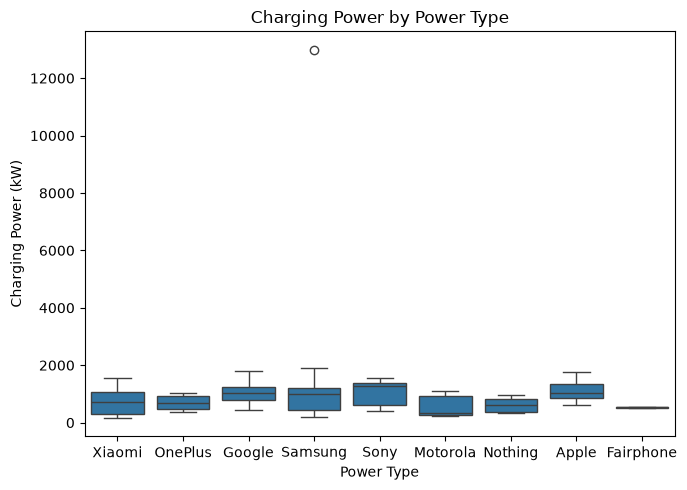

In [ ]:
# Korrigierten Code unter den Kommentaren eintragen

# Select columns for the analysis
df_B2 = df_clean[['brand', 'price_chf']]

# Price per brand
df_B2.groupby(['brand']).max().round(2).sort_values(by='price_chf', ascending=False)

#Boxplot
fig, ax = plt.subplots(figsize=(7, 5))                                          #Abbildung und Zeichenfläche erstellen; Grösse in Zoll
sns.boxplot(data=df_B2, x='brand', y='price_chf') 
ax.set_xlabel('Power Type')                                                     #X-Achse: Ladearten
ax.set_ylabel('Charging Power (kW)')                                            #Y-Achse: Ladeleistung
ax.set_title('Charging Power by Power Type')                                    #Diagrammtitel festlegen
plt.tight_layout()                                                              #Abstände optimieren
plt.show()                                                                      #Boxplot anzeigen



In [ ]:
df_B2.sort_values(by='price_chf', ascending=False)


,brand,price_chf
107,Samsung,12990.0
65,Samsung,1899.0
121,Google,1799.0
91,Google,1799.0
136,Samsung,1749.0
...,...,...
53,Google,NaN
82,Google,NaN
86,Samsung,NaN
126,Google,NaN


---
## Teil C – Python-Code schreiben (12 Punkte)

Schreiben Sie Python-Code und begründen Sie Ihre Vorgehensweise jeweils in 1–2 Sätzen. Worauf die Begründung eingehen soll, steht bei der Aufgabe.

### C1 (4 Punkte)

Die Datei `html/product_detail.html` enthält die Detailseite des Google Pixel 10 Pro. In der Code-Zelle ist bereits ein Gerüst vorgegeben, das die HTML-Datei einliest und eine Tabelle Zeile für Zeile in den Data Frame `df_C1` mit den Spalten `merkmal` und `wert` überführt.

Ergänzen Sie die beiden mit `# TODO` markierten Stellen:

1. Wählen Sie die Tabelle **«Technische Daten»** aus.
2. Entfernen Sie die Zwischenüberschriften der Tabelle (z.B. «Display») — sie sind **keine** Merkmale und dürfen im Ergebnis nicht vorkommen.

Begründen Sie, wie Sie die richtige Tabelle auswählen und die Zwischenüberschriften entfernen.

*Tipp: Öffnen Sie die HTML-Datei im Editor und sehen Sie sich `df_C1` vor dem Entfernen der Zwischenüberschriften an.*

**Begründung der Vorgehensweise:**

> [Hier eintragen]

**Python-Code:**

In [8]:
for table in soup.find_all('table'):
    print('ID:', table.get('id'), '| Klasse:', table.get('class'))

ID: None | Klasse: ['price-history']
ID: None | Klasse: ['spec-table']


In [ ]:
# Read html from file
with open('html/product_detail.html', 'r', encoding='utf-8') as file:
    html_content = file.read()

# Parse the HTML content
soup = BeautifulSoup(html_content, 'html.parser')

# TODO: Locate the table «Technische Daten»
table = soup.find('table', class_='spec-table')

# Extract table rows
rows = []
for row in table.find_all('tr'):
    rows.append([cell.get_text().strip() for cell in row.find_all('td')])

# Create a DataFrame
df_C1 = pd.DataFrame(rows, columns=['merkmal', 'wert'])

# TODO: Remove the sub-headings (e.g. «Display»)
df_C1 = df_C1.dropna(how='all').reset_index(drop=True)                          #Vollständig leere Zeilen entfernen
                                                                                #dropna(how='all'): Nur Zeilen entfernen, in denen ALLE Spalten NaN sind
                                                                                #reset_index(drop=True): Index neu nummerieren

# Show the result
df_C1

,merkmal,wert
0,Marke,Google
1,Modell,Pixel 10 Pro
2,Betriebssystem,Android 16
3,Erscheinungsdatum,28.08.2025
4,Gewicht,207 g
5,Bildschirmdiagonale,"6.3"""
6,Auflösung,1280 x 2856 Pixel
7,Bildwiederholrate,1–120 Hz
8,Akkukapazität,4'870 mAh
9,Prozessor,Google Tensor G5


### C2 (4 Punkte)

Teilen Sie die Geräte in `df_clean` anhand von `price_chf` mit `pd.qcut()` in **drei ungefähr gleich grosse Preisklassen** mit den Labels `günstig`, `mittel` und `teuer` ein (neue Spalte `segment`).

Erstellen Sie anschliessend mit `pd.crosstab()` eine Kontingenztabelle mit der Anzahl Geräte pro Marke (`brand`, Zeilen) und Preisklasse (`segment`, Spalten). Begründen Sie, wie `pd.qcut()` die Klassengrenzen bestimmt und was mit den Geräten ohne Preis geschieht.

**Begründung der Vorgehensweise:**

> [Hier eintragen]
- 'segment' erstellt eine neue Spalte im df_clean. Dessen Inhalt wird mit pd.cut bestimmmt. Dieses nimmt nämlich die bereits bestehende Spalte 'price_chf' und teilt sie in 3 bins ein
- pd.cut bestimmt die Klassengrössen, indem drei gleich breite Zahlenintervalle erstellt werden
- Geräte ohne Preis werden nicht inkludiert

In [22]:
display(df_clean)

,product_id,brand,model,storage_gb,color,screen_inch,battery_mah,price_chf,availability
0,PM-10001,Xiaomi,Redmi Note 14 Pro 5G,256,Midnight Black,6.67,5110,299.0,Sofort lieferbar
1,PM-10002,OnePlus,OnePlus 13,256,Arctic Dawn,6.82,6000,899.0,Lieferbar in 2–5 Tagen
2,PM-10003,Google,Pixel 10 Pro,512,Obsidian,6.30,4870,1249.0,Sofort lieferbar
3,PM-10004,Samsung,Galaxy A36 5G,128,Awesome Lavender,6.70,5000,339.0,Sofort lieferbar
4,PM-10005,Samsung,Galaxy Z Fold7,1024,Jetblack,8.00,4400,NaN,Vorbestellung
...,...,...,...,...,...,...,...,...,...
137,PM-10138,Samsung,Galaxy S25,256,Mint,6.20,4000,899.0,Sofort lieferbar
138,PM-10139,Samsung,Galaxy A36 5G,128,Awesome Black,6.70,5000,309.0,Vorbestellung
139,PM-10140,Google,Pixel 10 Pro Fold,512,Moonstone,8.00,5015,NaN,Lieferbar in 2–5 Tagen
140,PM-10141,Apple,iPhone 17 Pro,256,Silver,6.30,4252,1199.0,Lieferbar in 2–5 Tagen


**Python-Code:**

In [27]:
# Code hier eintragen
df_clean['segment'] = pd.cut(df_clean['price_chf'],                             #Kreiere neue Spalte "segment"
                              bins=3,                                           #Wertebereich in drei gleich breite Intervalle teilen
                              labels=['günstig', 'mittel', 'teuer'])  

display(df_clean[['price_chf', 'segment']].head(10))                            #Preise und neue Preisklassen nebeneinander anzeigen


ct = pd.crosstab(                   #Kreuztabelle erstellen und in ct speichern
    df_clean['brand'],              #Erste kategoriale Variable: Bestimmt die Zeilen der Tabelle
    df_clean['segment'],            #Zweite kategoriale Variable: Bestimmt die Spalten der Tabelle
    margins=True,                   #Zusätzliche Zeile und Spalte mit den Gesamtsummen hinzufügen
    margins_name='Total'            #Bezeichnung der Gesamtsummen auf 'Total' setzen
)
ct                                  #Kreuztabelle anzeigen

,price_chf,segment
0,299.0,günstig
1,899.0,günstig
2,1249.0,günstig
3,339.0,günstig
4,NaN,NaN
5,299.0,günstig
6,989.0,günstig
7,1549.0,günstig
8,379.0,günstig
9,249.0,günstig


segment,günstig,teuer,Total
brand,,,
Apple,34,0,34
Fairphone,2,0,2
Google,22,0,22
Motorola,6,0,6
Nothing,8,0,8
OnePlus,8,0,8
Samsung,29,1,30
Sony,6,0,6
Xiaomi,18,0,18


### C3 (4 Punkte)

Lesen Sie die Kundenbewertungen aus `reviews.json` in einen Data Frame ein und verbinden Sie ihn mit `.merge()` über `product_id` mit `df_clean`. Berechnen Sie die **Spearman-Rangkorrelation** zwischen `price_chf` und `avg_score` (gerundet auf 2 Dezimalstellen) und erstellen Sie ein Streudiagramm (Scatter Plot) mit beschrifteten Achsen.

Begründen Sie, welche Geräte nach dem `.merge()` im Data Frame enthalten sind, und interpretieren Sie das Ergebnis in 1–2 Sätzen.

**Begründung der Vorgehensweise:**

> [Hier eintragen]
- Reviews eingelesen, musste aber zuerst den korrekten Path finden, dieser dann der Variable json_path zugewiesen und diese wiederum in den DataFrame geladen
- Merge gemacht über product_id, wie verlangt & Spearman berechnet
- Scatterplot gefailt

**Python-Code:**

In [ ]:
from pathlib import Path

print('Aktuelles Arbeitsverzeichnis:', Path.cwd())                              #Ordner anzeigen, von dem relative Pfade ausgehen
print('Gefundene JSON-Dateien:', list(Path.cwd().rglob('*.json')))              #JSON-Dateien in diesem Ordner und Unterordnern suchen

Aktuelles Arbeitsverzeichnis: /workspaces/DS_HS2026_LNW/DS_HS2026_LNW_I_Examples/AP02/AP02 Mock Exam
Gefundene JSON-Dateien: [PosixPath('/workspaces/DS_HS2026_LNW/DS_HS2026_LNW_I_Examples/AP02/AP02 Mock Exam/reviews.json')]


Number of rows and columns: (128, 3)
Column names: ['product_id', 'review_count', 'avg_score']
Data types:
product_id          str
review_count      int64
avg_score       float64
dtype: object


,product_id,review_count,avg_score
0,PM-09871,412,4.1
1,PM-09874,158,3.6
2,PM-09902,233,4.4
3,PM-09917,61,2.9
4,PM-10001,133,3.0


,price_chf,avg_score
price_chf,1.00,0.76
avg_score,0.76,1.00


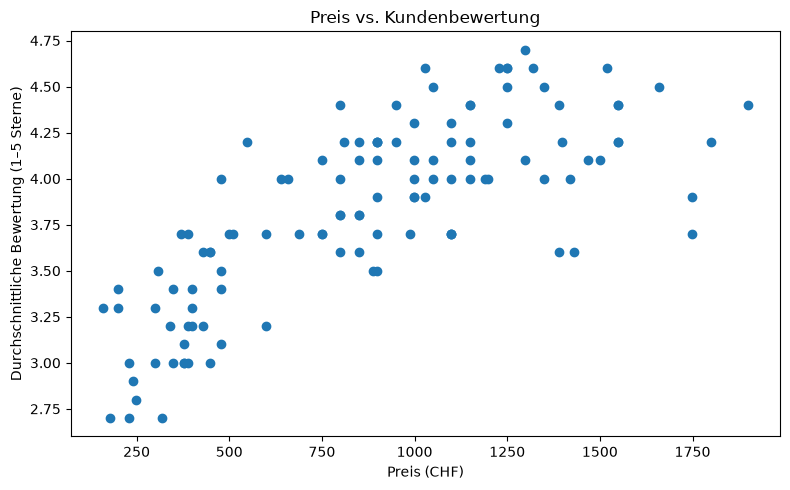

In [43]:
# Code hier eintragen
json_path = Path('/workspaces/DS_HS2026_LNW/DS_HS2026_LNW_I_Examples/AP02/AP02 Mock Exam/reviews.json')  
df_json = pd.read_json(json_path) 

# Show information about the data
print('Number of rows and columns:', df_json.shape)                             #Dimension des DataFrames als (Zeilen, Spalten) anzeigen
print('Column names:', df_json.columns.tolist())                                #Alle vorhandenen Spaltennamen als Liste anzeigen
print('Data types:')
print(df_json.dtypes)                                                           #Datentyp jeder Spalte anzeigen

# Print the data
display(df_json.head(5)) 


df_merged = df_json.merge(df_clean[['product_id',                               #Nur benötigte Spalten des zweiten DataFrames auswählen
                                'brand',       
                                'model',       
                                'price_chf',
                                ]], 
                         on="product_id")                                       #merge(): Beide DataFrames anhand der gemeinsamen Schlüsselspalte verbinden
                                                                                #on: Schlüsselspalte muss in beiden DataFrames vorhanden sein
                                                                                #Standard: how='inner' (nur übereinstimmende Schlüsselwerte übernehmen)
                                                                                #Erkenntnis: Fahrzeugdaten werden um geografische Informationen ergänzt
# SPEARMAN-RANGKORRELATION
num_cols = ['price_chf', 'avg_score']                                           #Numerische Spalten auswählen

corr = df_merged[num_cols].corr(method='spearman').round(2)                     #Spearman-Korrelationsmatrix berechnen und auf 2 Stellen runden
display(corr)                                                                   #Korrelationsmatrix anzeigen


#Scatterplot
# SCATTER PLOT

df_plot = df_merged.loc[df_merged['price_chf'] != 12990]          #Fehlerhaften Preis CHF 12'990 nur für die Visualisierung ausschliessen

fig, ax = plt.subplots(figsize=(8, 5))                          #Diagramm erstellen

ax.scatter(df_plot['price_chf'], df_plot['avg_score'])            #Preis gegen durchschnittliche Bewertung darstellen

ax.set_xlabel('Preis (CHF)')                                     #X-Achse beschriften
ax.set_ylabel('Durchschnittliche Bewertung (1–5 Sterne)')        #Y-Achse beschriften
ax.set_title('Preis vs. Kundenbewertung')                        #Diagrammtitel festlegen

plt.tight_layout()                                               #Abstände optimieren
plt.show()                                                       #Diagramm anzeigen

---
### Jupyter notebook --footer info-- (please always provide this at the end of each notebook)

In [ ]:
# Libraries
import os, platform, socket
from platform import python_version
from datetime import datetime

# Print system information
print('-----------------------------------')
print(os.name.upper())
print(platform.system(), '|', platform.release())
print('Datetime:', datetime.now().strftime('%Y-%m-%d %H:%M:%S'))
print('Python Version:', python_version())
print('IP Address:', socket.gethostbyname(socket.gethostname()))
print('-----------------------------------')